# Reweighted 2D FES and Kolmogorov-backward committor for AlaD alphaL

This notebook builds a reweighted free-energy surface (FES) in the 2D `(phi, psi)` space from the explicit-water AlaD exploration run, solves the Kolmogorov backward equation for the alphaL committor on that FES, and compares the result against the MSM and observed-local-stitch committors.

The KBE committor here is exact for the estimated 2D FES model and the assumed overdamped constant-diffusion dynamics on `(phi, psi)`. It is not an exact all-atom committor unless `(phi, psi)` is a complete Markovian reaction coordinate and the reweighted FES is converged.

## Method

1. Load the saved `cvs.npz` segments from `runs/alad_alphaL_explore_36x36`.
2. Estimate a reweighted equilibrium population on a regular 2D grid using a reversible transition-count estimator: adjacent saved frames define grid-state transitions, counts are symmetrized, and the stationary population is the row sum of the reversible count matrix.
3. Smooth the stationary population on the angular torus, then compute `F(phi, psi) = -kBT ln p(phi, psi)`.
4. Solve the backward equation `L q = 0`, with `q(source)=0` and `q(alphaL)=1`, using a nearest-neighbor finite-volume generator whose rates satisfy detailed balance against `exp(-beta F)`.
5. Compare KBE probe values against the final MSM and local-stitch probe values from the convergence reports.

In [1]:
from __future__ import annotations

import json
import math
import os
import sys
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/trails-md-matplotlib')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter
from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.linalg import spsolve

REPO_ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == 'AlaD' else Path.cwd().resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

RUN_DIR = REPO_ROOT / 'examples' / 'AlaD' / 'runs' / 'alad_alphaL_explore_36x36'
NOTEBOOK_OUTPUT_DIR = RUN_DIR / 'fes_kbe_notebook'
NOTEBOOK_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TARGET = 'alphaL'
BETA = 1.0
KB_T = 1.0 / BETA
FES_GRID = 72
SMOOTH_SIGMA_BINS = 1.0
PSEUDOCOUNT = 1.0e-12

PHI_PSI_LIMITS = (-np.pi, np.pi)
ALPHAL_BOX = ((0.35, 1.75), (0.05, 1.75))

msm_report = json.loads((RUN_DIR / 'alphaL_committor_convergence.json').read_text())
stitch_report = json.loads((RUN_DIR / 'alphaL_local_stitch_convergence.json').read_text())
SOURCE_CENTER = np.asarray(msm_report['source_center'], dtype=float)
SOURCE_HALF_WIDTH = float(msm_report['source_half_width'])

print(RUN_DIR)
print('source center:', SOURCE_CENTER, 'half width:', SOURCE_HALF_WIDTH)
print('alphaL box:', ALPHAL_BOX)

/home/dm/Dibyendu/GitHub/Trails-MD/examples/AlaD/runs/alad_alphaL_explore_36x36
source center: [-2.3664577   2.41705632] half width: 0.35
alphaL box: ((0.35, 1.75), (0.05, 1.75))


In [2]:
def iter_number(path: Path) -> int:
    return int(path.name.removeprefix('iter_'))

def load_iteration_segments(run_dir: Path) -> list[list[np.ndarray]]:
    iterations: list[list[np.ndarray]] = []
    for iter_dir in sorted(run_dir.glob('iter_*'), key=iter_number):
        cv_file = iter_dir / 'cvs.npz'
        if not cv_file.exists():
            continue
        with np.load(cv_file) as data:
            cvs = np.asarray(data['cvs'] if 'cvs' in data.files else data[data.files[0]], dtype=float)
        xtcs = sorted(iter_dir.glob(f'iteration_{iter_number(iter_dir)}_*.xtc'))
        if not xtcs:
            continue
        if cvs.shape[0] % len(xtcs) != 0:
            raise ValueError(f'{cv_file} frame count does not divide by walker count')
        iterations.append([chunk.copy() for chunk in np.split(cvs[:, :2], len(xtcs))])
    return iterations


def box_mask(points: np.ndarray, box: tuple[tuple[float, float], tuple[float, float]]) -> np.ndarray:
    pts = np.asarray(points, dtype=float)
    rows = pts.reshape(1, -1) if pts.ndim == 1 else pts
    mask = (
        (rows[:, 0] >= box[0][0]) & (rows[:, 0] <= box[0][1])
        & (rows[:, 1] >= box[1][0]) & (rows[:, 1] <= box[1][1])
    )
    return bool(mask[0]) if pts.ndim == 1 else mask


def source_mask(points: np.ndarray) -> np.ndarray:
    pts = np.asarray(points, dtype=float)
    rows = pts.reshape(1, -1) if pts.ndim == 1 else pts
    delta = np.abs(rows[:, :2] - SOURCE_CENTER[:2])
    mask = (delta[:, 0] <= SOURCE_HALF_WIDTH) & (delta[:, 1] <= SOURCE_HALF_WIDTH)
    return bool(mask[0]) if pts.ndim == 1 else mask


segments_by_iter = load_iteration_segments(RUN_DIR)
segments = [segment for iteration in segments_by_iter for segment in iteration]
points = np.vstack(segments)
print('iterations:', len(segments_by_iter))
print('segments:', len(segments))
print('frames:', len(points))
print('alphaL hits:', int(box_mask(points, ALPHAL_BOX).sum()))

iterations: 150
segments: 2400
frames: 48000
alphaL hits: 4061


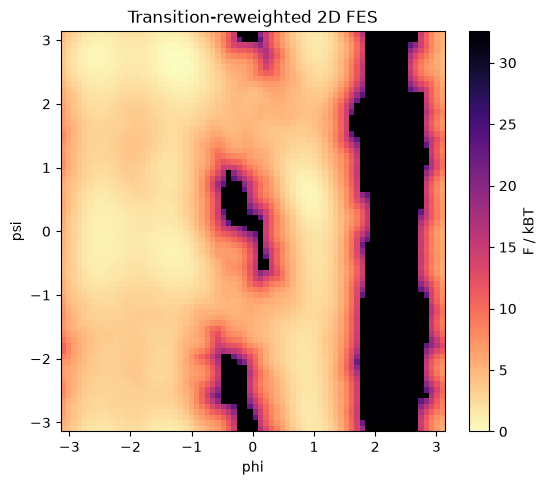

FES grid: 72 x 72
F range / kBT: 0.0 32.57516413363102


In [4]:
def grid_edges(n: int) -> np.ndarray:
    return np.linspace(-np.pi, np.pi, n + 1)

def grid_centers(edges: np.ndarray) -> np.ndarray:
    return 0.5 * (edges[:-1] + edges[1:])

def state_ids(cvs: np.ndarray, n: int) -> np.ndarray:
    scaled = (cvs[:, :2] + np.pi) / (2.0 * np.pi)
    ij = np.floor(scaled * n).astype(int)
    ij = np.mod(ij, n)
    return ij[:, 0] * n + ij[:, 1]


def reversible_transition_population(segments: list[np.ndarray], n: int, pseudocount: float) -> np.ndarray:
    n_states = n * n
    counts = np.zeros((n_states, n_states), dtype=float)
    for segment in segments:
        ids = state_ids(segment, n)
        for left, right in zip(ids[:-1], ids[1:]):
            counts[int(left), int(right)] += 1.0
    reversible_counts = 0.5 * (counts + counts.T)
    population = reversible_counts.sum(axis=1).reshape(n, n)
    population = gaussian_filter(population + pseudocount, sigma=SMOOTH_SIGMA_BINS, mode='wrap')
    population = np.maximum(population, pseudocount)
    return population / population.sum()


edges = grid_edges(FES_GRID)
xs = grid_centers(edges)
ys = grid_centers(edges)
population = reversible_transition_population(segments, FES_GRID, PSEUDOCOUNT)
fes = -KB_T * np.log(population)
fes -= np.nanmin(fes)

fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(fes.T, origin='lower', extent=(-np.pi, np.pi, -np.pi, np.pi), aspect='auto', cmap='magma_r')
ax.set_title('Transition-reweighted 2D FES')
ax.set_xlabel('phi')
ax.set_ylabel('psi')
fig.colorbar(im, ax=ax, label='F / kBT')
fig.savefig(NOTEBOOK_OUTPUT_DIR / 'reweighted_fes.png', dpi=200)
plt.show()

print('FES grid:', FES_GRID, 'x', FES_GRID)
print('F range / kBT:', float(fes.min()), float(fes.max()))

## Kolmogorov backward equation on the FES

For overdamped dynamics on the estimated FES, the backward equation is `Lq=0` outside the basins, with `q(A)=0` and `q(B)=1`. The finite-volume generator below uses nearest-neighbor rates

`k(i -> j) = D / h^2 * exp[-beta * (F_j - F_i) / 2]`,

which satisfy detailed balance with the reweighted population `exp(-beta F)`. The angular boundaries are treated as periodic.

In [5]:
def solve_kbe_from_fes(fes: np.ndarray, xs: np.ndarray, ys: np.ndarray, beta: float = 1.0, diffusion: float = 1.0):
    n_x, n_y = fes.shape
    dx = float(xs[1] - xs[0])
    dy = float(ys[1] - ys[0])
    x_grid, y_grid = np.meshgrid(xs, ys, indexing='ij')
    grid_points = np.stack([x_grid, y_grid], axis=-1)
    is_a = source_mask(grid_points.reshape(-1, 2)).reshape(n_x, n_y)
    is_b = box_mask(grid_points.reshape(-1, 2), ALPHAL_BOX).reshape(n_x, n_y)
    state = np.arange(n_x * n_y).reshape(n_x, n_y)
    operator = lil_matrix((n_x * n_y, n_x * n_y), dtype=float)
    rhs = np.zeros(n_x * n_y, dtype=float)

    for i in range(n_x):
        for j in range(n_y):
            row = int(state[i, j])
            if is_a[i, j]:
                operator[row, row] = 1.0
                continue
            if is_b[i, j]:
                operator[row, row] = 1.0
                rhs[row] = 1.0
                continue

            total_rate = 0.0
            neighbors = [((i - 1) % n_x, j, dx), ((i + 1) % n_x, j, dx), (i, (j - 1) % n_y, dy), (i, (j + 1) % n_y, dy)]
            for ni, nj, spacing in neighbors:
                rate = diffusion / (spacing * spacing) * math.exp(-0.5 * beta * float(fes[ni, nj] - fes[i, j]))
                total_rate += rate
                operator[row, int(state[ni, nj])] += rate
            operator[row, row] -= total_rate

    q = spsolve(csr_matrix(operator), rhs).reshape(n_x, n_y)
    residual = np.full((n_x, n_y), np.nan, dtype=float)
    for i in range(n_x):
        for j in range(n_y):
            if is_a[i, j] or is_b[i, j]:
                continue
            accum = 0.0
            neighbors = [((i - 1) % n_x, j, dx), ((i + 1) % n_x, j, dx), (i, (j - 1) % n_y, dy), (i, (j + 1) % n_y, dy)]
            for ni, nj, spacing in neighbors:
                rate = diffusion / (spacing * spacing) * math.exp(-0.5 * beta * float(fes[ni, nj] - fes[i, j]))
                accum += rate * (q[ni, nj] - q[i, j])
            residual[i, j] = accum
    return q, is_a, is_b, residual


q_kbe, is_a, is_b, residual = solve_kbe_from_fes(fes, xs, ys, beta=BETA)
print('q range:', float(np.nanmin(q_kbe)), float(np.nanmax(q_kbe)))
print('max interior |Lq|:', float(np.nanmax(np.abs(residual))))

q range: 0.0 1.0
max interior |Lq|: 8.287649178040368e-10


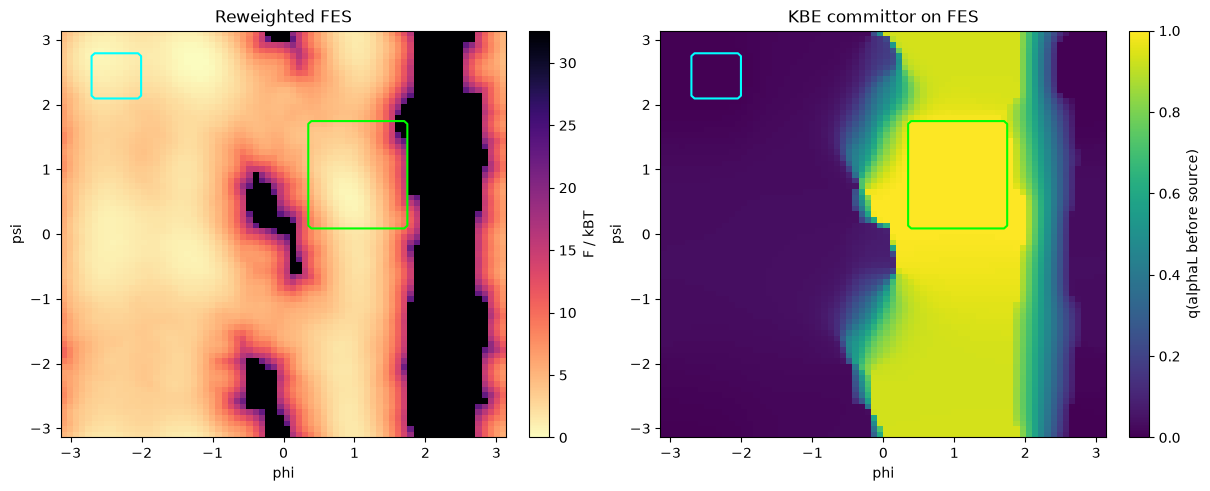

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)

im0 = axes[0].imshow(fes.T, origin='lower', extent=(-np.pi, np.pi, -np.pi, np.pi), aspect='auto', cmap='magma_r')
axes[0].contour(xs, ys, is_a.T.astype(float), levels=[0.5], colors='cyan', linewidths=1.5)
axes[0].contour(xs, ys, is_b.T.astype(float), levels=[0.5], colors='lime', linewidths=1.5)
axes[0].set_title('Reweighted FES')
axes[0].set_xlabel('phi')
axes[0].set_ylabel('psi')
fig.colorbar(im0, ax=axes[0], label='F / kBT')

im1 = axes[1].imshow(q_kbe.T, origin='lower', extent=(-np.pi, np.pi, -np.pi, np.pi), aspect='auto', vmin=0, vmax=1, cmap='viridis')
axes[1].contour(xs, ys, is_a.T.astype(float), levels=[0.5], colors='cyan', linewidths=1.5)
axes[1].contour(xs, ys, is_b.T.astype(float), levels=[0.5], colors='lime', linewidths=1.5)
axes[1].set_title('KBE committor on FES')
axes[1].set_xlabel('phi')
axes[1].set_ylabel('psi')
fig.colorbar(im1, ax=axes[1], label='q(alphaL before source)')
fig.savefig(NOTEBOOK_OUTPUT_DIR / 'fes_and_kbe_committor.png', dpi=200)
plt.show()

In [7]:
def box_center(box: tuple[tuple[float, float], tuple[float, float]]) -> np.ndarray:
    return np.array([0.5 * (box[0][0] + box[0][1]), 0.5 * (box[1][0] + box[1][1])], dtype=float)


def make_probe_points(source_center: np.ndarray, target_center: np.ndarray, count: int) -> np.ndarray:
    t = np.linspace(0.0, 1.0, int(count))
    return (1.0 - t)[:, None] * source_center[None, :] + t[:, None] * target_center[None, :]


def nearest_grid_values(xs: np.ndarray, ys: np.ndarray, values: np.ndarray, probes: np.ndarray) -> np.ndarray:
    out = np.zeros(len(probes), dtype=float)
    for idx, point in enumerate(probes):
        i = int(np.argmin(np.abs(xs - point[0])))
        j = int(np.argmin(np.abs(ys - point[1])))
        out[idx] = values[i, j]
    return out


msm_final = msm_report['rows'][-1]
stitch_final = stitch_report['rows'][-1]
probe_count = len(msm_final['probe_q'])
probes = make_probe_points(SOURCE_CENTER, box_center(ALPHAL_BOX), probe_count)

comparison = pd.DataFrame({
    'probe': np.arange(probe_count),
    'phi': probes[:, 0],
    'psi': probes[:, 1],
    'q_kbe_fes': nearest_grid_values(xs, ys, q_kbe, probes),
    'q_msm': np.asarray(msm_final['probe_q'], dtype=float),
    'q_local_stitch': np.asarray(stitch_final['probe_q'], dtype=float),
})
comparison['kbe_minus_msm'] = comparison['q_kbe_fes'] - comparison['q_msm']
comparison['kbe_minus_local_stitch'] = comparison['q_kbe_fes'] - comparison['q_local_stitch']
comparison

,probe,phi,psi,q_kbe_fes,q_msm,q_local_stitch,kbe_minus_msm,kbe_minus_local_stitch
0,0,-2.366458,2.417056,0.000000,0.000000,0.000000,0.000000,0.000000
1,1,-2.195635,2.341204,0.000000,0.000000,0.000000,0.000000,0.000000
2,2,-2.024812,2.265351,0.000000,0.007708,0.000000,-0.007708,0.000000
3,3,-1.853989,2.189498,0.007939,0.007708,0.001615,0.000231,0.006324
4,4,-1.683166,2.113645,0.015079,0.015036,0.003225,0.000043,0.011854
5,5,-1.512343,2.037792,0.020155,0.015036,0.003523,0.005119,0.016632
6,6,-1.341520,1.961939,0.024209,0.020025,0.004668,0.004184,0.019541
7,7,-1.170698,1.886087,0.028331,0.020025,0.004345,0.008306,0.023987
8,8,-0.999875,1.810234,0.034783,0.027951,0.003886,0.006833,0.030897
9,9,-0.829052,1.734381,0.049627,0.027951,0.004504,0.021677,0.045123


In [8]:
def rmse(a: np.ndarray, b: np.ndarray) -> float:
    return float(np.sqrt(np.nanmean((np.asarray(a) - np.asarray(b)) ** 2)))


summary = {
    'frames': int(len(points)),
    'alphaL_hits': int(box_mask(points, ALPHAL_BOX).sum()),
    'fes_grid': int(FES_GRID),
    'kbe_max_abs_residual': float(np.nanmax(np.abs(residual))),
    'rmse_kbe_vs_msm_probe': rmse(comparison['q_kbe_fes'], comparison['q_msm']),
    'rmse_kbe_vs_local_stitch_probe': rmse(comparison['q_kbe_fes'], comparison['q_local_stitch']),
    'rmse_msm_vs_local_stitch_probe': rmse(comparison['q_msm'], comparison['q_local_stitch']),
    'msm_status': msm_final['status'],
    'local_stitch_status': stitch_final['status'],
    'msm_final_probe_rmse_from_previous': msm_final['probe_rmse_from_previous'],
    'local_stitch_final_probe_rmse_from_previous': stitch_final['probe_rmse_from_previous'],
}
(NOTEBOOK_OUTPUT_DIR / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
comparison.to_csv(NOTEBOOK_OUTPUT_DIR / 'probe_comparison.csv', index=False)
summary

{'frames': 48000,
 'alphaL_hits': 4061,
 'fes_grid': 72,
 'kbe_max_abs_residual': 8.287649178040368e-10,
 'rmse_kbe_vs_msm_probe': 0.14579416681777996,
 'rmse_kbe_vs_local_stitch_probe': 0.09594957870705917,
 'rmse_msm_vs_local_stitch_probe': 0.14758589314596518,
 'msm_status': 'ok',
 'local_stitch_status': 'ok',
 'msm_final_probe_rmse_from_previous': 0.14517435419456104,
 'local_stitch_final_probe_rmse_from_previous': 5.429996330587298e-05}

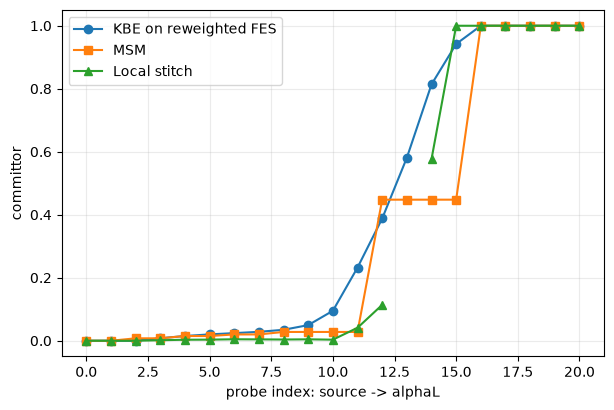

,probe,q_kbe_fes,q_msm,q_local_stitch,kbe_minus_msm,kbe_minus_local_stitch
0,0,0.000000,0.000000,0.000000,0.000000,0.000000
1,1,0.000000,0.000000,0.000000,0.000000,0.000000
2,2,0.000000,0.007708,0.000000,-0.007708,0.000000
3,3,0.007939,0.007708,0.001615,0.000231,0.006324
4,4,0.015079,0.015036,0.003225,0.000043,0.011854
5,5,0.020155,0.015036,0.003523,0.005119,0.016632
6,6,0.024209,0.020025,0.004668,0.004184,0.019541
7,7,0.028331,0.020025,0.004345,0.008306,0.023987
8,8,0.034783,0.027951,0.003886,0.006833,0.030897
9,9,0.049627,0.027951,0.004504,0.021677,0.045123


In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(comparison['probe'], comparison['q_kbe_fes'], marker='o', label='KBE on reweighted FES')
ax.plot(comparison['probe'], comparison['q_msm'], marker='s', label='MSM')
ax.plot(comparison['probe'], comparison['q_local_stitch'], marker='^', label='Local stitch')
ax.set_xlabel('probe index: source -> alphaL')
ax.set_ylabel('committor')
ax.set_ylim(-0.05, 1.05)
ax.legend()
ax.grid(alpha=0.25)
fig.savefig(NOTEBOOK_OUTPUT_DIR / 'probe_committor_comparison.png', dpi=200)
plt.show()

comparison[['probe', 'q_kbe_fes', 'q_msm', 'q_local_stitch', 'kbe_minus_msm', 'kbe_minus_local_stitch']]

## Interpretation checklist

- A small KBE residual confirms the backward equation was solved accurately on the estimated FES grid.
- Agreement with local stitch is expected only where the 2D projected dynamics are close to Markovian and the observed first-exit grid has enough support.
- Agreement with MSM is expected only after alphaL is in the active transition submodel; in this run the MSM convergence report first becomes `ok` at end-iteration 72.
- Disagreement is physically meaningful: it reflects either non-Markovianity in `(phi, psi)`, finite-data error in the FES, adaptive-sampling reweighting limitations, or insufficient grid resolution.